In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier ,AdaBoostClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay


I0000 00:00:1776168270.007106    8693 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1776168270.009675    8693 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1776168270.291100    8693 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1776168271.558742    8693 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

Der MNIST-Datensatz wird geladen, skaliert und von 2D-Bilddaten in 1D-Feature-Vektoren umgeformt. Danach werden die in der Gruppe gewählten Basismodelle für das Stacking definiert.

In [3]:
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [4]:
x_train = x_train / 255.0
x_test = x_test / 255.0

In [5]:
X_train = x_train.reshape(60000, 28*28)
X_test = x_test.reshape(10000, 28*28)

In [5]:
Decision_Tree = DecisionTreeClassifier(
    max_depth=14,
    min_samples_leaf=1,
    criterion="entropy",
    random_state=42
)

Decision_Tree.fit(X_train, y_train)
test_acc = Decision_Tree.score(X_test, y_test)
print("Final Test Accuracy:", test_acc)

Final Test Accuracy: 0.8855


In [6]:
knn_orig = KNeighborsClassifier(n_neighbors= 3)

knn_orig.fit(X_train, y_train)

y_pred_knn = knn_orig.predict(X_test)

knn_acc_orig = accuracy_score(y_test, y_pred_knn)

print("kNN Accuracy (original):", knn_acc_orig)

kNN Accuracy (original): 0.9705


In [7]:
rf_final = RandomForestClassifier(max_depth=20, n_estimators=150, random_state=208, min_samples_leaf=1, max_features="sqrt" )
rf_final.fit(X_train, y_train)
finaler_score = rf_final.score(X_test, y_test)
print(f"Finales Ergebnis Random Forest:{finaler_score}")

Finales Ergebnis Random Forest:0.9697


In [8]:
lr_A = LogisticRegression(
    solver   = 'saga',    # Stochastic Average Gradient – gut für großes N
    max_iter = 100,       # Epochen
    C        = 1.0,       # Regularisierung: C = 1/λ
    n_jobs   = -1,        # alle CPU-Kerne
    random_state = 42
)
lr_A.fit(X_train, y_train)
test_acc_lg = lr_A.score(X_test, y_test)
print("Final Test Accuracy:", test_acc_lg)

/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Final Test Accuracy: 0.9263


/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Zunächst wird ein einfaches Stacking-Modell ohne gezielte Optimierung getestet. Dieser Lauf dient nur als erste Orientierung und wird später mit den per Cross-Validation ausgewählten Konfigurationen verglichen.

In [16]:
estimators = [
    ("tree", DecisionTreeClassifier(max_depth=14, min_samples_leaf=1, criterion="entropy", random_state=42)),
    ("knn", KNeighborsClassifier(n_neighbors=3)),
    ("rf", RandomForestClassifier(max_depth=20, n_estimators=150, random_state=208)),
    ("lr_A", LogisticRegression(solver="saga", max_iter=100, C=1.0, random_state=42))
]

stack_clf = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(),
    cv=5
)

stack_clf.fit(X_train, y_train)

y_pred_stack = stack_clf.predict(X_test)
stack_acc = accuracy_score(y_test, y_pred_stack)

print("Stacking Accuracy:", stack_acc)

/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the 

Stacking Accuracy: 0.9785


Im nächsten Schritt werden verschiedene Meta-Klassifizierer in einfachen Einstellungen per StratifiedKFold-Cross-Validation verglichen. Zusätzlich wird passthrough = True/False getestet, um zu prüfen, ob die ursprünglichen Eingabedaten dem Meta-Modell zusätzlich helfen. Die Anzahl der Folds wird aus Laufzeitgründen auf 3 reduziert.

In [ ]:

# Basis-Modelle
estimators = [
    ("tree", DecisionTreeClassifier(max_depth=14, min_samples_leaf=1, criterion="entropy", random_state=42)),
    ("knn", KNeighborsClassifier(n_neighbors=3)),
    ("rf", RandomForestClassifier(max_depth=20, n_estimators=150, random_state=208)),
    ("lr_A", LogisticRegression(solver="saga", max_iter=100, C=1.0,random_state=42))
]

# Meta-Modelle in default settings
meta_models = {
    "LogReg": LogisticRegression(random_state=42, max_iter=100),
    "DecisionTree": DecisionTreeClassifier(random_state=42),
    "RandomForest": RandomForestClassifier(random_state=42),
    "kNN": KNeighborsClassifier()
}

# passthrough-Werte
passthrough_values = [True, False]

outer_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

results = []

for passthrough in passthrough_values:
    for meta_name, meta_model in meta_models.items():
        print(f"Teste Meta-Classifier: {meta_name}, passthrough={passthrough}")

        stack_clf = StackingClassifier(
            estimators=estimators,
            final_estimator=meta_model,
            stack_method="predict_proba",
            passthrough=passthrough,
            cv=3,
        )

        cv_results = cross_validate(
            stack_clf,
            X_train,
            y_train,
            cv=outer_cv,
            scoring="accuracy",
            return_train_score=True,
        )

        results.append({
            "meta_classifier": meta_name,
            "passthrough": passthrough,
            "cv_mean_accuracy": np.mean(cv_results["test_score"]),
            "cv_std": np.std(cv_results["test_score"]),
            "train_mean_accuracy": np.mean(cv_results["train_score"])
        })

results_df = pd.DataFrame(results).sort_values("cv_mean_accuracy", ascending=False)
print(results_df)

Teste Meta-Classifier: LogReg, passthrough=True


/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 i

Teste Meta-Classifier: DecisionTree, passthrough=True


/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the 

Teste Meta-Classifier: RandomForest, passthrough=True


/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the 

... (7 outputs left out)

/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the 

Teste Meta-Classifier: kNN, passthrough=False


/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the 

  meta_classifier  passthrough  cv_mean_accuracy    cv_std  \
6    RandomForest        False          0.978717  0.001578   
4          LogReg        False          0.977583  0.001581   
0          LogReg         True          0.977300  0.000960   
2    RandomForest         True          0.977017  0.001934   
7             kNN        False          0.973767  0.001286   
3             kNN         True          0.972733  0.001140   
5    DecisionTree        False          0.965833  0.000944   
1    DecisionTree         True          0.964417  0.001829   

   train_mean_accuracy  
6             0.997950  
4             0.999375  
0             0.999950  
2             0.999592  
7             0.995800  
3             0.986458  
5             0.989150  
1             0.989058  


Random Forest und logistische Regression liefern im Test die besten Ergebnisse als Meta-Klassifizierer. Der Random Forest liegt zwar leicht vorn, der Abstand zur logistischen Regression mit passthrough = False ist aber klein. Daher wird die logistische Regression als einfacheres Meta-Modell weiterverfolgt und im nächsten Schritt genauer untersucht.

In [13]:
valid_combinations = [
    {"solver": "lbfgs", "penalty": "l2"},
    {"solver": "saga", "penalty": "l2"},
    {"solver": "saga", "penalty": "l1"}
]

results = []

for combo in valid_combinations:
    solver = combo["solver"]
    penalty = combo["penalty"]

    meta_model = LogisticRegression(
        solver=solver,
        penalty=penalty,
        max_iter= 100,
        random_state=42
    )

    stack_clf = StackingClassifier(
        estimators=estimators,
        final_estimator=meta_model,
        stack_method="predict_proba",
        passthrough=False,
        cv=3
    )

    cv_results = cross_validate(
        stack_clf,
        X_train,
        y_train,
        cv=outer_cv,
        scoring="accuracy",
        return_train_score=True
    )

    results.append({
        "solver": solver,
        "penalty": penalty,
        "cv_mean_accuracy": np.mean(cv_results["test_score"]),
        "cv_std": np.std(cv_results["test_score"]),
        "train_mean_accuracy": np.mean(cv_results["train_score"])
    })

results_df = pd.DataFrame(results).sort_values("cv_mean_accuracy", ascending=False)
print(results_df)

/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 

  solver penalty  cv_mean_accuracy    cv_std  train_mean_accuracy
2   saga      l1          0.977950  0.001592             0.999542
1   saga      l2          0.977800  0.001512             0.999408
0  lbfgs      l2          0.977583  0.001581             0.999375


Die Kombination aus "solver = saga" und "penalty = l1" liefert im getesteten Vergleich die beste Cross-Validation-Accuracy. Daher wird sie im nächsten Schritt beibehalten, während die Hyperparameter "C" und "max_iter" weiterhin untersucht werden.

In [8]:


# Basis-Modelle
estimators = [
    ("tree", DecisionTreeClassifier(max_depth=14, min_samples_leaf=1, criterion="entropy", random_state=42)),
    ("knn", KNeighborsClassifier(n_neighbors=3)),
    ("rf", RandomForestClassifier(max_depth=20, n_estimators=150, random_state=208)),
    ("lr_A" , LogisticRegression(solver='saga', max_iter=100,C= 1.0 , random_state= 42))
]

results = []

C_values = [0.1, 1.0, 10.0]
max_iter_values = [100, 300, 500]

for C in C_values:
    for max_it in max_iter_values:
        print(f"Teste Meta-LogReg: C={C}, max_iter={max_it}")

        stack_clf = StackingClassifier(
            estimators=estimators,
            final_estimator=LogisticRegression(
                C=C,
                max_iter=max_it,
                solver="saga",
                penalty="l1",
                random_state=42
            ),
            stack_method="predict_proba",
            passthrough=False,
            cv=3,
        )

        scores = cross_val_score(
            stack_clf,
            X_train,
            y_train,
            cv=3,
            scoring="accuracy",
        )

        results.append({
            "meta_C": C,
            "meta_max_iter": max_it,
            "cv_mean_accuracy": scores.mean(),
            "cv_std": scores.std()
        })

        print(f" -> CV Accuracy: {scores.mean():.4f}")
        print(f" -> Std: {scores.std():.4f}\n")

results_df = pd.DataFrame(results).sort_values(
    ["cv_mean_accuracy", "cv_std"],
    ascending=[False, True]
)

print(results_df)

Teste Meta-LogReg: C=0.1, max_iter=100


/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 

 -> CV Accuracy: 0.9748
 -> Std: 0.0007

Teste Meta-LogReg: C=0.1, max_iter=300


/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 

 -> CV Accuracy: 0.9748
 -> Std: 0.0007

Teste Meta-LogReg: C=0.1, max_iter=500


/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 

... (9 outputs left out)

/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 

 -> CV Accuracy: 0.9771
 -> Std: 0.0003

Teste Meta-LogReg: C=10.0, max_iter=500


/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 

 -> CV Accuracy: 0.9771
 -> Std: 0.0004

   meta_C  meta_max_iter  cv_mean_accuracy    cv_std
8    10.0            500          0.977133  0.000357
7    10.0            300          0.977100  0.000324
6    10.0            100          0.977100  0.000402
3     1.0            100          0.977100  0.000502
4     1.0            300          0.977100  0.000502
5     1.0            500          0.977100  0.000502
0     0.1            100          0.974817  0.000726
1     0.1            300          0.974817  0.000726
2     0.1            500          0.974817  0.000726


Die ersten Tests zeigen, dass höhere Werte von "C" tendenziell zu besseren Ergebnissen führen. Auch größere Werte für "max_iter" schneiden insgesamt etwas besser ab als niedrigere Einstellungen.  
Daher werden im nächsten Schritt höhere Werte für "C" und "max_iter" getestet, um zu prüfen, ob sich die Leistung des Meta-Klassifizierers weiter verbessern lässt.

In [18]:


# Basis-Modelle
estimators = [
    ("tree", DecisionTreeClassifier(max_depth=14, min_samples_leaf=1, criterion="entropy", random_state=42)),
    ("knn", KNeighborsClassifier(n_neighbors=3)),
    ("rf", RandomForestClassifier(max_depth=20, n_estimators=150, random_state=208)),
    ("lr_A" , LogisticRegression(solver='saga', max_iter=100,C= 1.0 , random_state= 42))
]

results = []

C_values = [10.0, 30.0, 60.0]
max_iter_values = [500, 700 ,900]

for C in C_values:
    for max_it in max_iter_values:
        print(f"Teste Meta-LogReg: C={C}, max_iter={max_it}")

        stack_clf = StackingClassifier(
            estimators=estimators,
            final_estimator=LogisticRegression(
                C=C,
                max_iter=max_it,
                solver="saga",
                penalty="l1",
                random_state=42
            ),
            stack_method="predict_proba",
            passthrough=False,
            cv=3,
        )

        scores = cross_val_score(
            stack_clf,
            X_train,
            y_train,
            cv=3,
            scoring="accuracy",
        )

        results.append({
            "meta_C": C,
            "meta_max_iter": max_it,
            "cv_mean_accuracy": scores.mean(),
            "cv_std": scores.std()
        })

        print(f" -> CV Accuracy: {scores.mean():.4f}")
        print(f" -> Std: {scores.std():.4f}\n")

results_df = pd.DataFrame(results).sort_values(
    ["cv_mean_accuracy", "cv_std"],
    ascending=[False, True]
)

print(results_df)

Teste Meta-LogReg: C=10.0, max_iter=500


/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 

 -> CV Accuracy: 0.9771
 -> Std: 0.0004

Teste Meta-LogReg: C=10.0, max_iter=700


/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 

 -> CV Accuracy: 0.9771
 -> Std: 0.0004

Teste Meta-LogReg: C=10.0, max_iter=900


/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 

... (9 outputs left out)

/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 

 -> CV Accuracy: 0.9771
 -> Std: 0.0004

Teste Meta-LogReg: C=60.0, max_iter=900


/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 

 -> CV Accuracy: 0.9771
 -> Std: 0.0004

   meta_C  meta_max_iter  cv_mean_accuracy    cv_std
0    10.0            500          0.977133  0.000357
1    10.0            700          0.977133  0.000357
2    10.0            900          0.977133  0.000357
5    30.0            900          0.977100  0.000402
3    30.0            500          0.977083  0.000397
4    30.0            700          0.977083  0.000397
6    60.0            500          0.977083  0.000411
7    60.0            700          0.977083  0.000411
8    60.0            900          0.977050  0.000374


Die bisherigen Tests zeigen bereits ein weitgehend stabiles Leistungsniveau.Da jedoch mehrfach Konvergenzwarnungen ("max_iter was reached") auftraten, wird "max_iter" in einem weiteren Schritt noch erhöht.Damit soll überprüft werden, ob sich die Optimierung des Meta-Klassifizierers stabilisieren lässt.

In [6]:
estimators = [
    ("tree", DecisionTreeClassifier(max_depth=14, min_samples_leaf=1, criterion="entropy", random_state=42)),
    ("knn", KNeighborsClassifier(n_neighbors=3)),
    ("rf", RandomForestClassifier(max_depth=20, n_estimators=150, random_state=208)),
    ("lr_A", LogisticRegression(solver="saga", max_iter=100, C=1.0, random_state=42))
]

results = []

fixed_C = 10.0
max_iter_values = [500, 1000, 1500]

for max_it in max_iter_values:
    print(f"Teste Meta-LogReg: C={fixed_C}, max_iter={max_it}")

    stack_clf = StackingClassifier(
        estimators=estimators,
        final_estimator=LogisticRegression(
            C=fixed_C,
            max_iter=max_it,
            solver="saga",
            penalty="l1",
            random_state=42
        ),
        stack_method="predict_proba",
        passthrough=False,
        cv=3,
    )

    scores = cross_val_score(
        stack_clf,
        X_train,
        y_train,
        cv=3,
        scoring="accuracy",
    )

    results.append({
        "meta_C": fixed_C,
        "meta_max_iter": max_it,
        "cv_mean_accuracy": scores.mean(),
        "cv_std": scores.std()
    })

    print(f" -> CV Accuracy: {scores.mean():.4f}")
    print(f" -> Std: {scores.std():.4f}\n")

results_df = pd.DataFrame(results).sort_values(
    ["cv_mean_accuracy", "cv_std"],
    ascending=[False, True]
)

print(results_df)

Teste Meta-LogReg: C=10.0, max_iter=500


/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 

 -> CV Accuracy: 0.9771
 -> Std: 0.0004

Teste Meta-LogReg: C=10.0, max_iter=1000


/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 

 -> CV Accuracy: 0.9771
 -> Std: 0.0004

Teste Meta-LogReg: C=10.0, max_iter=1500


/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 

 -> CV Accuracy: 0.9771
 -> Std: 0.0004

   meta_C  meta_max_iter  cv_mean_accuracy    cv_std
0    10.0            500          0.977133  0.000357
1    10.0           1000          0.977133  0.000357
2    10.0           1500          0.977133  0.000357


In [7]:
# Basis-Modelle
estimators = [
    ("tree", DecisionTreeClassifier(max_depth=14, min_samples_leaf=1, criterion="entropy", random_state=42)),
    ("knn", KNeighborsClassifier(n_neighbors=3)),
    ("rf", RandomForestClassifier(max_depth=20, n_estimators=150, random_state=208)),
    ("lr_A", LogisticRegression(solver="saga", max_iter=100, C=1.0, random_state=42))
]

results = []

fixed_C = 10.0
max_iter_values = [2000, 3000, 4000]

for max_it in max_iter_values:
    print(f"Teste Meta-LogReg: C={fixed_C}, max_iter={max_it}")

    stack_clf = StackingClassifier(
        estimators=estimators,
        final_estimator=LogisticRegression(
            C=fixed_C,
            max_iter=max_it,
            solver="saga",
            penalty="l1",
            random_state=42
        ),
        stack_method="predict_proba",
        passthrough=False,
        cv=3,
    )

    scores = cross_val_score(
        stack_clf,
        X_train,
        y_train,
        cv=3,
        scoring="accuracy",
    )

    results.append({
        "meta_C": fixed_C,
        "meta_max_iter": max_it,
        "cv_mean_accuracy": scores.mean(),
        "cv_std": scores.std()
    })

    print(f" -> CV Accuracy: {scores.mean():.4f}")
    print(f" -> Std: {scores.std():.4f}\n")

results_df = pd.DataFrame(results).sort_values(
    ["cv_mean_accuracy", "cv_std"],
    ascending=[False, True]
)

print(results_df)

Teste Meta-LogReg: C=10.0, max_iter=2000


/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 

 -> CV Accuracy: 0.9771
 -> Std: 0.0004

Teste Meta-LogReg: C=10.0, max_iter=3000


/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 

 -> CV Accuracy: 0.9771
 -> Std: 0.0004

Teste Meta-LogReg: C=10.0, max_iter=4000


/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 

 -> CV Accuracy: 0.9771
 -> Std: 0.0004

   meta_C  meta_max_iter  cv_mean_accuracy    cv_std
0    10.0           2000          0.977133  0.000357
1    10.0           3000          0.977133  0.000357
2    10.0           4000          0.977133  0.000357


Eine weitere Erhöhung von "max_iter" brachte keine Verbesserung der CV-Ergebnisse. Da "max_iter = 500" bei "C = 10.0" bereits dieselbe Leistung wie höhere Werte erreichte, wird diese Konfiguration wegen der geringeren Laufzeit für das finale Modell verwendet.
Die Konvergenzwarnungen scheinen dabei eher vom Basis-Modell der logistischen Regression auszugehen.

In [11]:
estimators = [
    ("tree", DecisionTreeClassifier(max_depth=14, min_samples_leaf=1, criterion="entropy", random_state=42)),
    ("knn", KNeighborsClassifier(n_neighbors=3)),
    ("rf", RandomForestClassifier(max_depth=20, n_estimators=150, random_state=208)),
    ("lr_A" , LogisticRegression(solver='saga', max_iter=100,C= 1.0 , random_state= 42))
]

stack_clf = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(
        max_iter= 500,
        C = 10.0 ,
        solver= "saga",
        penalty = "l1"),
    stack_method="predict_proba",
    cv=3,
)

stack_clf.fit(X_train, y_train)

y_pred_stack = stack_clf.predict(X_test)
stack_acc = accuracy_score(y_test, y_pred_stack)

print("Stacking Accuracy:", stack_acc)

/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 

Stacking Accuracy: 0.9795


Das finale Modell erreicht eine leicht verbesserte Test-Accuracy von 97.95 %. Die gewählte Konfiguration spricht für eine günstigere Leistung bei schwächerer Regularisierung.

In [12]:

cm_stack = confusion_matrix(y_test, y_pred_stack)
print("Confusion Matrix:")
print(cm_stack)

Confusion Matrix:
[[ 974    1    1    0    0    0    2    1    1    0]
 [   0 1128    1    2    0    1    2    0    1    0]
 [   4    0 1012    3    1    0    0   10    2    0]
 [   0    0    2  983    1    9    0    6    6    3]
 [   0    0    1    0  960    0    4    2    2   13]
 [   2    0    0    6    1  875    3    1    2    2]
 [   6    2    0    0    4    2  941    0    3    0]
 [   0    7    9    2    2    0    0 1002    0    6]
 [   3    0    2    8    3    3    1    4  946    4]
 [   2    4    2    8    9    3    1    3    3  974]]


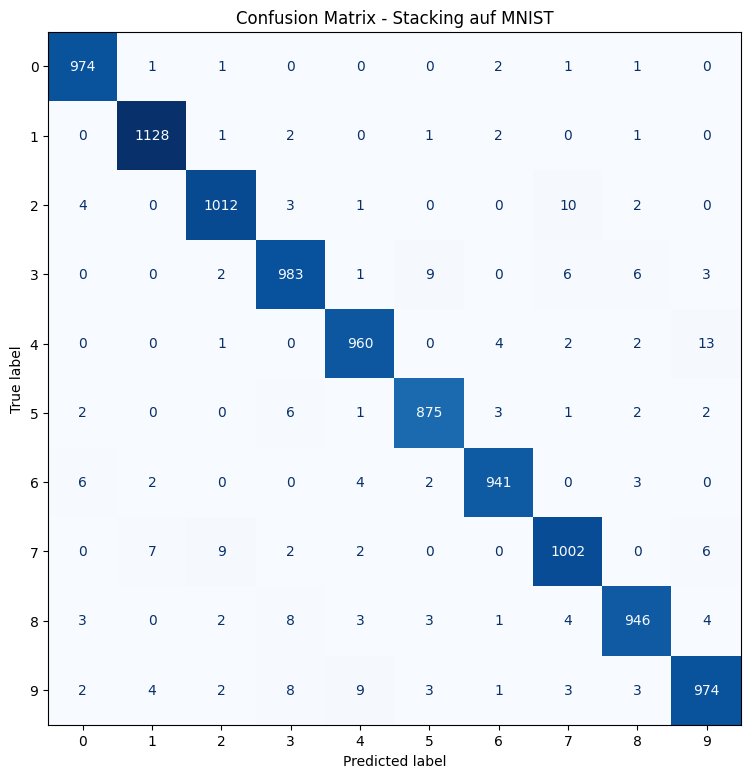

In [13]:
fig, ax = plt.subplots(figsize=(9, 9))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_stack,
    display_labels=[str(i) for i in range(10)]
)
disp.plot(cmap="Blues", ax=ax, values_format="d", colorbar=False)
plt.title("Confusion Matrix - Stacking auf MNIST")
plt.show()

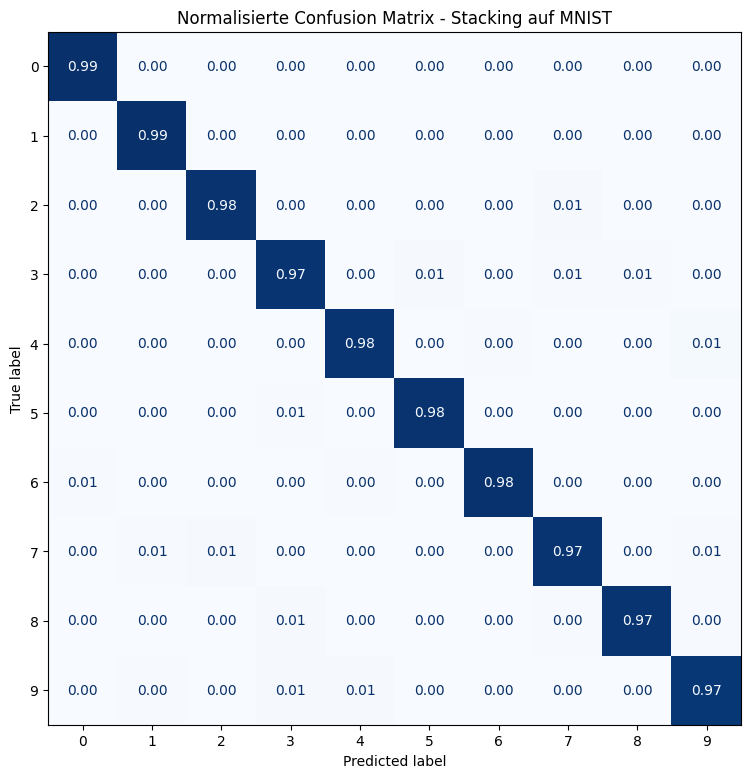

In [14]:
cm_stack_norm = confusion_matrix(y_test, y_pred_stack, normalize="true")

fig, ax = plt.subplots(figsize=(9, 9))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_stack_norm,
    display_labels=[str(i) for i in range(10)]
)
disp.plot(cmap="Blues", ax=ax, values_format=".2f", colorbar=False)
plt.title("Normalisierte Confusion Matrix - Stacking auf MNIST")
plt.show()

Die Matrix ist deutlich diagonal geprägt und bestätigt die hohe Klassifikationsleistung des finalen Stacking-Modells. Verbleibende Fehlklassifikationen konzentrieren sich vor allem auf visuell ähnliche Klassen, insbesondere "2/7, "3/5" und "4/9". Gegenüber dem einzelnen Modellen, besonders dem DecisionTree und der Logistischen Regression treten die Fehler deutlich seltener auf, was auf eine robustere Generalisierung des Ensemble-Modells hinweist.

Der einzelne Decision Tree wird hier durch einen AdaBoost-Klassifizierer ersetzt, um zu prüfen, ob die Gesamtleistung des Stackings verbessert wird.

In [19]:
estimators = [
    ("boosted_tree", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=10,
            min_samples_leaf=1,
            random_state=42
        ),
        n_estimators=600,
        learning_rate=0.3,
        random_state=42
    )),
    ("knn", KNeighborsClassifier(n_neighbors=3)),
    ("rf", RandomForestClassifier(
        max_depth=20,
        n_estimators=150,
        random_state=208
    )),
    ("lr_A", LogisticRegression(
        solver="saga",
        max_iter=100,
        C=1.0,
        random_state=42
    ))
]

stackada_clf = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(
        max_iter=500,
        C=10.0,
        solver="saga",
        penalty="l1",
        random_state=42
    ),
    stack_method="predict_proba",
    passthrough=False,
    cv=3
)

stackada_clf.fit(X_train, y_train)

y_pred_stackada = stackada_clf.predict(X_test)
stackada_acc = accuracy_score(y_test, y_pred_stackada)

print("Stacking Accuracy:", stackada_acc)

/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 

Stacking Accuracy: 0.9789


In [20]:


cm_stackada = confusion_matrix(y_test, y_pred_stackada)
print("Confusion Matrix:")
print(cm_stackada)

Confusion Matrix:
[[ 973    1    1    0    0    0    3    1    1    0]
 [   0 1128    1    2    0    1    2    0    1    0]
 [   4    0 1010    3    1    0    0   10    4    0]
 [   0    0    2  981    1   12    0    6    5    3]
 [   0    0    0    0  960    0    4    2    3   13]
 [   2    0    0    7    2  873    3    1    2    2]
 [   6    2    0    0    4    3  940    0    3    0]
 [   0    5    9    2    2    0    0 1003    1    6]
 [   3    0    2    8    3    3    1    4  946    4]
 [   2    4    3    7    8    2    1    4    3  975]]


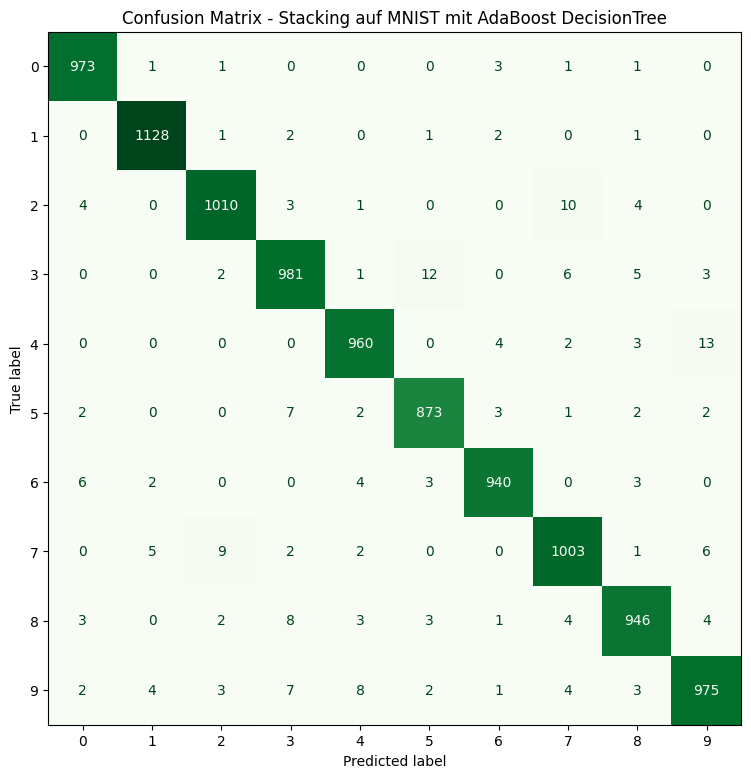

In [21]:
fig, ax = plt.subplots(figsize=(9, 9))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_stackada,
    display_labels=[str(i) for i in range(10)]
)
disp.plot(cmap="Greens", ax=ax, values_format="d", colorbar=False)
plt.title("Confusion Matrix - Stacking auf MNIST mit AdaBoost DecisionTree")
plt.show()

Beide Stacking-Modelle zeigen nahezu identische Fehlermuster. Das AdaBoost-Stacking verbessert einzelne Klassen leicht, verschlechtert jedoch andere, insbesondere bei Verwechslungen wie 3/5 und 2/8. Insgesamt ergibt sich kein klarer systematischer Vorteil gegenüber dem normalen Stacking-Modell.

Das Stacking-Modell mit AdaBoost-DecisionTree anstelle des einzelnen DecisionTree in den Basis-Modellen erreicht eine Test-Accuracy von 97,89 %. Es liegt damit leicht über dem einfachen Stacking-Modell ohne weitere Optimierung (97,85 %), aber weiterhin unter dem Stacking-Modell mit abgestimmtem Meta-Klassifizierer (97,95 %). Der Austausch des Basis-Decision-Trees bringt somit nur einen geringen Zusatznutzen. Für eine belastbare Bewertung wären weitere Tests sinnvoll, in denen die Hyperparameter des Meta-Klassifizierers speziell auf diese neue Modellkombination abgestimmt werden.